### 🎓 Module 04: Gradient Descent for Machine Learning

In this Jupyter Notebook, we will connect **Calculus, Linear Algebra, Optimization, and Machine Learning** by implementing **Gradient Descent from scratch using NumPy**.

Until now, we have solved Linear Regression using the **Normal Equation**, which provides a direct closed-form solution for the optimal parameter vector. However, many Machine Learning models do not have a practical closed-form solution, so we need an iterative optimization algorithm capable of improving the model parameters step by step.

Gradient Descent is based on a fundamental idea from multivariable calculus:

> The gradient points in the direction of the maximum local increase of a function. Therefore, the negative gradient points in the direction of the steepest local decrease.

Our objective is to minimize a cost function $J(\theta)$:

$$\min_{\theta} J(\theta)$$

The general Gradient Descent update rule is:

$$\theta^{(k+1)} = \theta^{(k)} - \alpha \nabla J(\theta^{(k)})$$

where $\alpha$ is the **learning rate**, which controls the size of each optimization step.

### AI and ML Concepts We Will Use:

* **Parameters ($\theta$)**: Values learned by the model. In Linear Regression, they contain the bias and the feature weights.
* **Bias ($\theta_0$)**: The intercept term of the model. It represents the prediction when all input features are equal to zero.
* **Weights ($\theta_j$)**: Coefficients associated with each input feature.
* **Features ($x_j$)**: Independent input variables used by the model.
* **N° Samples ($m$)**: Number of training examples in the dataset.
* **N° Features ($n$)**: Number of independent variables used by the model.
* **Parameter Vector ($\theta$)**: Column vector containing the bias and all feature weights.
* **Design Matrix ($X$)**: Matrix with dimensions $m \times (n+1)$. Its first column contains ones for the bias term, while the remaining columns contain the feature values.
* **Prediction Vector ($\hat{y}$)**: Model predictions generated from the current parameters.
* **Residual Vector ($r$)**: Difference between predictions and real target values:
* **Cost Function ($J(\theta)$)**: Mathematical function that measures how well the current parameters fit the training data.
* **Mean Squared Error (MSE)**: Average squared prediction error.
* **Gradient ($\nabla J$)**: Vector containing all partial derivatives of the cost function with respect to the model parameters.
* **Learning Rate ($\alpha$)**: Positive scalar controlling the step size of each Gradient Descent update.
* **Iteration**: One complete calculation of the gradient followed by one parameter update.
* **Convergence**: The process by which the optimization algorithm approaches a stable minimum of the cost function.
* **Feature Scaling**: Transformation of features to comparable numerical scales in order to improve Gradient Descent convergence.

### The Core Mathematical Equations:

**1. Simple Linear Regression Model:**

$$\hat{y} = \theta_0 + \theta_1 x$$

**2. Multiple Linear Regression Model:**

$$\hat{y} = X\theta$$

**3. Linear Regression Cost Function:**

$$J(\theta) = \frac{1}{2m}(X\theta - y)^T(X\theta - y)$$

The factor $\frac{1}{2}$ is mathematically convenient because it cancels the factor $2$ generated when differentiating the squared error.

**4. Gradient of the Cost Function:**

$$\nabla J(\theta) = \frac{1}{m}X^T(X\theta - y)$$

This equation gives one partial derivative for every model parameter.

**5. Batch Gradient Descent Update Rule:**

$$\theta^{(k+1)} = \theta^{(k)} - \frac{\alpha}{m}X^T(X\theta^{(k)} - y)$$

During Batch Gradient Descent, the entire training dataset is used to calculate the gradient before updating the parameters.

### Connection with the Normal Equation:

At the minimum of a differentiable convex cost function:

$$\nabla J(\theta) = 0$$

For Linear Regression:

$$X^T(X\theta - y) = 0$$

Expanding the equation:

$$X^TX\theta = X^Ty$$

If $X^TX$ is invertible, we obtain the Normal Equation:

$$\theta = (X^TX)^{-1}X^Ty$$

Therefore, the Normal Equation and Gradient Descent solve the same optimization problem using two different mathematical approaches:

* **Normal Equation:** Direct closed-form solution.
* **Gradient Descent:** Iterative numerical optimization.

### Practical Goals of This Notebook:

1. Implement Gradient Descent for a simple one-dimensional mathematical function.
2. Visualize the effect of different learning rates.
3. Generate a synthetic dataset using NumPy.
4. Implement Simple Linear Regression with Gradient Descent.
5. Implement Multiple Linear Regression using the Design Matrix.
6. Calculate predictions, residuals, cost, and gradients using vectorized matrix operations.
7. Store and visualize the cost history to study convergence.
8. Implement feature standardization manually.
9. Compare unscaled and standardized features.
10. Compare the final Gradient Descent parameters with the Normal Equation solution.

The central Machine Learning loop developed in this notebook is:

$$\theta \rightarrow \hat{y} \rightarrow J(\theta) \rightarrow \nabla J(\theta) \rightarrow \text{Update } \theta \rightarrow \text{Repeat}$$

In [1]:
# Import the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configure Numpy output & set a reproducible random seed
np.set_printoptions(precision=6, suppress=True)

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

In [2]:
# Define a one-dimensional objective function and its derivative

def objective_function(x):
    return x ** 2

def objective_gradient(x):
    return 2 * x

# Define a reusable one-dimensional Gradient Descent function
def gradient_descent_1d(initial_x, learning_rate, n_iterations):
    x = float(initial_x)
    history = [x] # Save each step history in a python list
    
    for _ in range(n_iterations):
        gradient = objective_gradient(x)
        x = x - learning_rate * gradient
        history.append(x)
        
    return np.array(history)

# Define the optimization configuration
INITIAL_X = 10
LEARNING_RATE = 0.1
N_ITERATIONS = 20

# Run Gradient Descent
x_history = gradient_descent_1d(INITIAL_X, LEARNING_RATE, N_ITERATIONS)

# Visualization of the optimization path in a DataFrame
pd.DataFrame({
    'iteration': np.arange(len(x_history)),
    'x': x_history,
    'f(x)': objective_function(x_history)
}) 

,iteration,x,f(x)
0,0,10.000000,100.000000
1,1,8.000000,64.000000
2,2,6.400000,40.960000
3,3,5.120000,26.214400
4,4,4.096000,16.777216
5,5,3.276800,10.737418
6,6,2.621440,6.871948
7,7,2.097152,4.398047
8,8,1.677722,2.814750
9,9,1.342177,1.801440


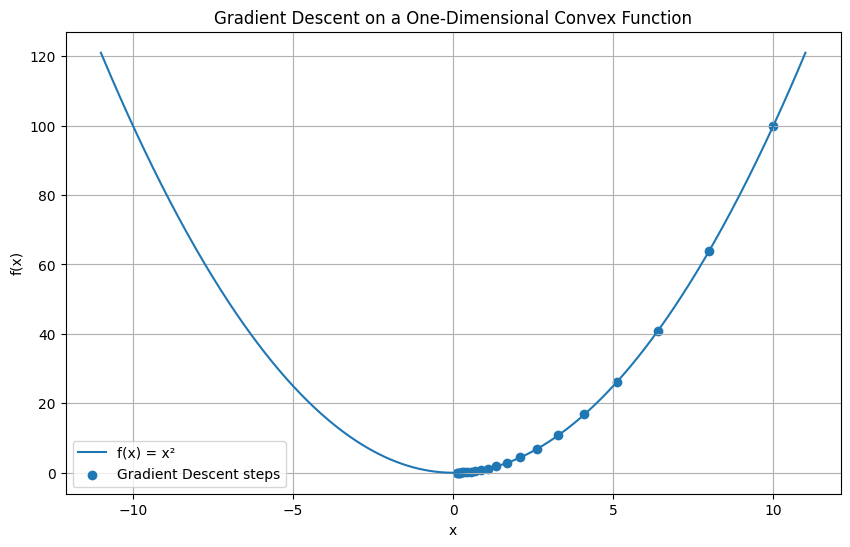

In [3]:
# Plot the one-dimensional objective function and optimization path

x_values = np.linspace(-11, 11, 500)
y_values = objective_function(x_values)

plt.figure(figsize=(10, 6))
plt.plot(x_values, y_values, label="f(x) = x²")
plt.scatter(x_history, objective_function(x_history), label="Gradient Descent steps")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Gradient Descent on a One-Dimensional Convex Function")
plt.legend()
plt.grid(True)
plt.show()


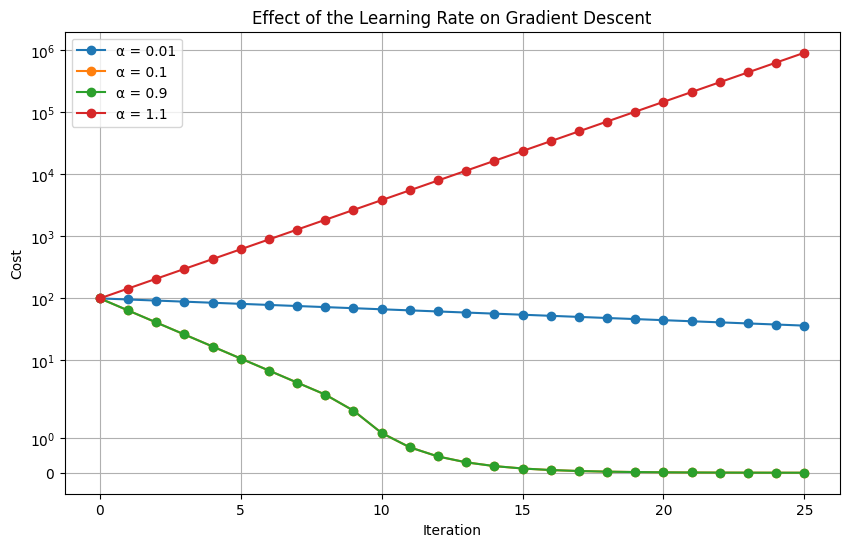

In [4]:
# Compare different learning rates

learning_rates = [0.01, 0.1, 0.9, 1.1]
comparison_iterations = 25

plt.figure(figsize=(10, 6))

for learning_rate in learning_rates:
    history = gradient_descent_1d(
        initial_x=INITIAL_X,
        learning_rate=learning_rate,
        n_iterations=comparison_iterations
    )

    plt.plot(
        np.arange(len(history)),
        objective_function(history),
        marker="o",
        label=f"α = {learning_rate}"
    )

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Effect of the Learning Rate on Gradient Descent")
plt.yscale("symlog")
plt.legend()
plt.grid(True)
plt.show()


### Simple Linear Regression Example 

In [5]:
# Generate a synthetic dataset for Simple Linear Regression

M_SAMPLES = 200

true_theta_0 = 4.0
true_theta_1 = 2.5
noise_std = 2.0

x_simple = rng.uniform(0, 20, size=M_SAMPLES)
noise = rng.normal(0, noise_std, size=M_SAMPLES)

y_simple = true_theta_0 + true_theta_1 * x_simple + noise

# Store the dataset in a DataFrame
simple_data = pd.DataFrame({
    'feature': x_simple,
    'target': y_simple
})

print(simple_data.head())
print()
print(simple_data.describe())

     feature     target
0  15.479121  43.984456
1   8.777569  25.154712
2  17.171958  46.919652
3  13.947361  38.541516
4   1.883547   9.384016

          feature      target
count  200.000000  200.000000
mean     9.877391   28.726287
std      5.646232   14.625291
min      0.147245    0.954127
25%      5.044329   15.656546
50%      9.580084   28.152460
75%     14.944884   42.317443
max     19.847511   56.129176


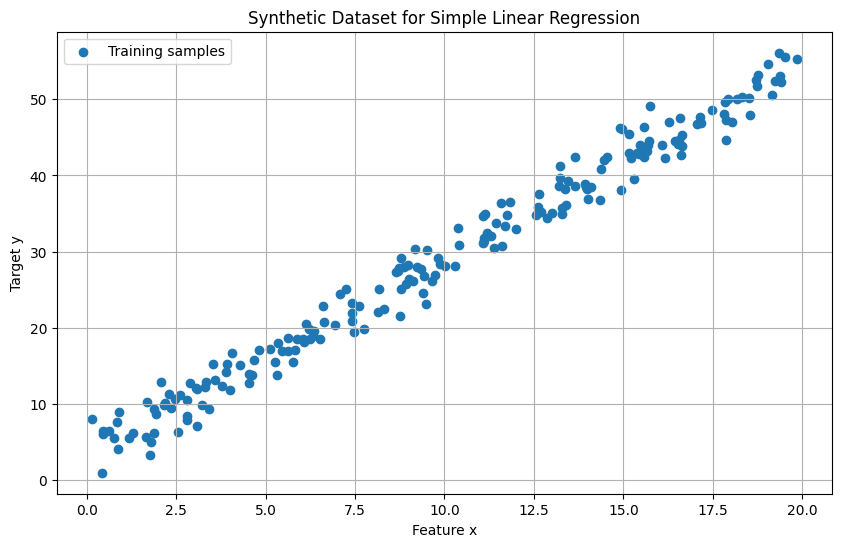

In [6]:
# Visualize the synthetic Simple Linear Regression dataset

plt.figure(figsize=(10, 6))
plt.scatter(x_simple, y_simple, label='Training samples')
plt.xlabel("Feature x")
plt.ylabel("Target y")
plt.title("Synthetic Dataset for Simple Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
# Define the Mean Squared Error cost function

def compute_cost(X, y, theta):
    m = X.shape[0]
    residuals = X @ theta - y
    
    cost = (1 / (2*m)) * (residuals.T @ residuals)
    
    return float(cost)

# Define the Batch Gradient Descent using vectorized matrix operations

def batch_gradient_descent(X, y, learning_rate, n_iterations, theta_initial=None):
    m, n_parameters = X.shape
    
    if theta_initial is None:
        theta = np.zeros(n_parameters)
    else:
        theta = np.asarray(theta_initial, dtype=float).copy()
        
    cost_history = np.zeros(n_iterations)
    gradient_norm_history = np.zeros(n_iterations)
    
    for iteration in range(n_iterations):
        predictions = X @ theta
        residuals = predictions - y
        
        gradient = (1/m) * (X.T @ residuals)
        
        theta = theta - learning_rate * gradient
        
        cost_history[iteration] = compute_cost(X, y, theta)
        gradient_norm_history[iteration] = np.linalg.norm(gradient)
    
    return theta, cost_history, gradient_norm_history

In [12]:
# Now we build the Design Matrix for Simple Linear Regression
X_simple_matrix = np.column_stack((np.ones(M_SAMPLES), x_simple))

# Define the Gradient Descent configuration
LEARNING_RATE_SIMPLE = 0.01
N_ITERATIONS_SIMPLE = 3000

# Train the model
theta_simple, cost_history_simple, gradient_norm_history_simple = batch_gradient_descent(
    X = X_simple_matrix,
    y = y_simple,
    learning_rate=LEARNING_RATE_SIMPLE,
    n_iterations=N_ITERATIONS_SIMPLE
)

# Display the learned parameters
print('Learned parameters:')
print(f'Theta_0: {theta_simple[0]:.6f}')
print(f'Theta_1: {theta_simple[1]:.6f}')

print()
print('True parameters used to generate the dataset:')
print(f'Theta_0: {true_theta_0:.6f}')
print(f'Theta_1: {true_theta_1:.6f}')


Learned parameters:
Theta_0: 3.379600
Theta_1: 2.566080

True parameters used to generate the dataset:
Theta_0: 4.000000
Theta_1: 2.500000


In [13]:
# Calculate the final predictions and residuals
y_simple_pred = X_simple_matrix @ theta_simple
simple_residuals = y_simple_pred - y_simple

# Create a results DataFrame
simple_results = pd.DataFrame({
    "feature": x_simple,
    "target": y_simple,
    "prediction": y_simple_pred,
    "residual": simple_residuals
})

simple_results

,feature,target,prediction,residual
0,15.479121,43.984456,43.100268,-0.884188
1,8.777569,25.154712,25.903547,0.748835
2,17.171958,46.919652,47.444225,0.524573
3,13.947361,38.541516,39.169648,0.628132
4,1.883547,9.384016,8.212933,-1.171084
...,...,...,...,...
195,3.585366,13.072123,12.579938,-0.492185
196,11.987656,33.025588,34.140888,1.115300
197,17.491241,48.646874,48.263529,-0.383344
198,3.928693,15.225641,13.460943,-1.764698


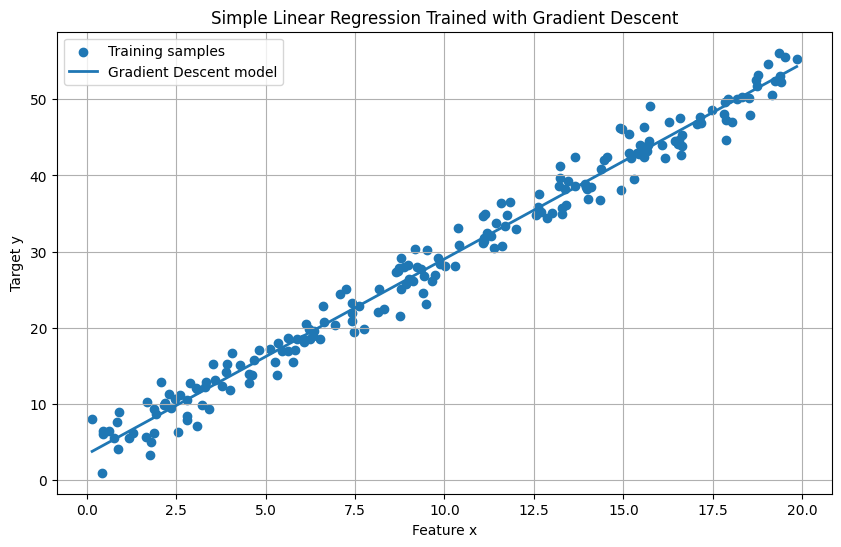

In [10]:
# Visualize the fitted regression line

sorted_indices = np.argsort(x_simple)

plt.figure(figsize=(10, 6))
plt.scatter(x_simple, y_simple, label="Training samples")
plt.plot(
    x_simple[sorted_indices],
    y_simple_pred[sorted_indices],
    linewidth=2,
    label="Gradient Descent model"
)
plt.xlabel("Feature x")
plt.ylabel("Target y")
plt.title("Simple Linear Regression Trained with Gradient Descent")
plt.legend()
plt.grid(True)
plt.show()

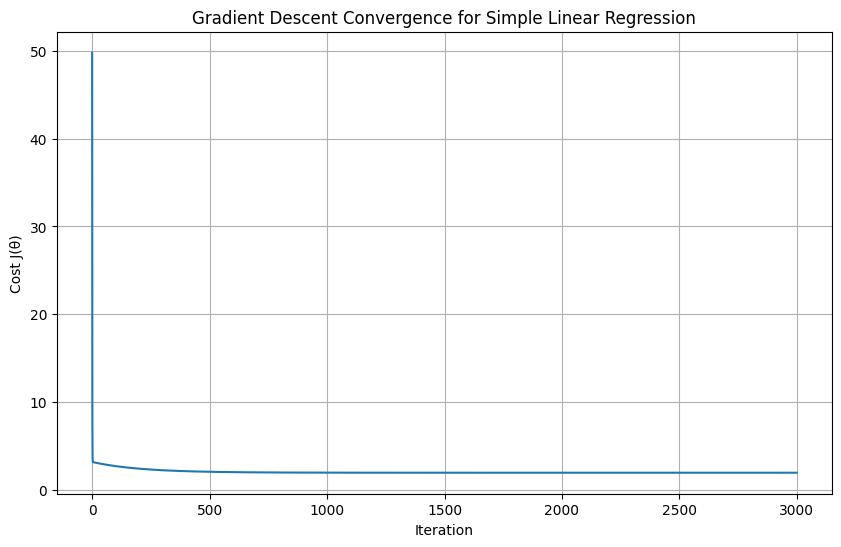

In [14]:
# Visualize the cost history

plt.figure(figsize=(10, 6))
plt.plot(cost_history_simple)
plt.xlabel("Iteration")
plt.ylabel("Cost J(θ)")
plt.title("Gradient Descent Convergence for Simple Linear Regression")
plt.grid(True)
plt.show()

### Multiple Linear Regression Example

In [ ]:
# 1. Generate a synthetic dataset for Multiple Linear Regression
M_SAMPLES_MULTIPLE = 1000
N_FEATURES = 4

# Generate features with intentionally different numerical scales
production_rate = rng.normal(150, 8, M_SAMPLES_MULTIPLE)
furnace_temperature = rng.normal(800, 15, M_SAMPLES_MULTIPLE)
operation_hours = rng.normal(18, 1.2, M_SAMPLES_MULTIPLE)
ambient_temperature = rng.normal(25, 6, M_SAMPLES_MULTIPLE)

# Build the feature matrix with out the bias column
X_multiple_raw = np.column_stack((production_rate, furnace_temperature, operation_hours, ambient_temperature))

# Define the true parameters
true_theta_multiple = np.array([120.0, 4.0, 0.8, 15.0, -2.5])

# Build the desing matrix
bias_column = np.ones(M_SAMPLES_MULTIPLE)
X_multiple = np.column_stack((bias_column, X_multiple_raw))

# Generate the target with gaussian noise
multiple_noise = rng.normal(0, 12, M_SAMPLES_MULTIPLE)
y_multiple = X_multiple @ true_theta_multiple + multiple_noise

# Store the synthetic dataset in a DataFrame (4 raw columns x + 1 y column called energy_consumption)
multiple_data = pd.DataFrame(
    X_multiple_raw,
    columns = ['Production Rate', 'Furnace Temperature', 'Operation Hours', 'Ambient Temperature']
)

multiple_data['Energy Consumption'] = y_multiple

multiple_data.head()

,Production Rate,Furnace Temperature,Operation Hours,Ambient Temperature,Energy Consumption
0,146.001017,795.940749,18.823255,36.878221,1530.376272
1,153.278965,832.372977,18.720393,19.102154,1637.625297
2,137.609613,786.494201,17.818844,40.933078,1459.530748
3,150.648288,806.565685,17.699396,23.097569,1569.478187
4,156.784603,793.182633,17.133591,17.979076,1593.604829


In [25]:
# 2. Inspect the Multiple Linear Regression Dataset
print('Dataset shape:')
print(multiple_data.shape)
print()

print('Dataset statistics:')
multiple_data.describe()

Dataset shape:
(1000, 5)

Dataset statistics:


,Production Rate,Furnace Temperature,Operation Hours,Ambient Temperature,Energy Consumption
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,150.525192,800.769764,17.953514,24.887005,1570.213200
std,8.021251,15.821589,1.198181,5.993119,43.629932
min,122.915899,748.034549,14.093268,6.335264,1419.444463
25%,145.073659,789.524808,17.157550,20.789777,1542.114467
50%,150.631660,800.739064,17.924529,24.880659,1571.307910
75%,155.951042,811.755775,18.665611,29.154068,1598.287852
max,175.807945,855.237643,22.018324,42.103535,1704.910016


In [ ]:
# 3. Define a manual feature standarization function 
# Centers the data around 0 with a standard deviation of 1

def standardize_features(X):
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    X_scaled = (X - mean) / std
    
    return X_scaled, mean, std

# Standardize the feature matrix
X_multiple_scaled_raw, feature_mean, feature_std = standardize_features(X_multiple_raw)

# Rebuild the design matrix with the bias column
X_multiple_scaled = np.column_stack((bias_column, X_multiple_scaled_raw))

# Verify the scaled features statistics
scaled_data = pd.DataFrame(
    X_multiple_scaled_raw,
    columns = ['Production Rate', 'Furnace Temperature', 'Operation Hours', 'Ambient Temperature'] 
)

scaled_data.head()

,Production Rate,Furnace Temperature,Operation Hours,Ambient Temperature
0,-0.564306,-0.305370,0.726248,2.001832
1,0.343481,1.998473,0.640357,-0.965732
2,-1.610976,-0.902735,-0.112451,2.678756
3,0.015354,0.366513,-0.212192,-0.298731
4,0.780744,-0.479783,-0.684649,-1.153220


In [41]:
# 4. Train Multiple Linear Regression on unscaled features

LEARNING_RATE_UNESCALED = 0.000001
N_ITERATIONS_MULTIPLE = 5000

theta_unscaled, cost_history_unscaled, gradient_norm_unscaled = batch_gradient_descent(
    X = X_multiple,
    y = y_multiple,
    learning_rate = LEARNING_RATE_UNESCALED,
    n_iterations = N_ITERATIONS_MULTIPLE
)

print('Final Cost with unscaled features:')
print(f'COST UNSCALED = {cost_history_unscaled[-1]:.2f}')

print()
print('Learned parameters with unscaled features:')
print(theta_unscaled)

Final Cost with unscaled features:
COST UNSCALED = 587.00

Learned parameters with unscaled features:
[ 0.003479  1.476782  1.688945  0.160171 -0.306228]


In [44]:
# 5. Train Multiple Linear Regression on standardized features

LEARNING_RATE_SCALED = 0.05

theta_scaled, cost_history_scaled, gradient_norm_scaled = batch_gradient_descent(
    X = X_multiple_scaled,
    y = y_multiple,
    learning_rate = LEARNING_RATE_SCALED,
    n_iterations = N_ITERATIONS_MULTIPLE
)

print("Final cost with standardized features:")
print(f'COST SCALED = {cost_history_scaled[-1]:.2f}')

print()
print("Learned parameters in standardized feature space:")
print(theta_scaled)

Final cost with standardized features:
COST SCALED = 76.65

Learned parameters in standardized feature space:
[1570.2132     32.168139   12.761291   17.557692  -15.283463]


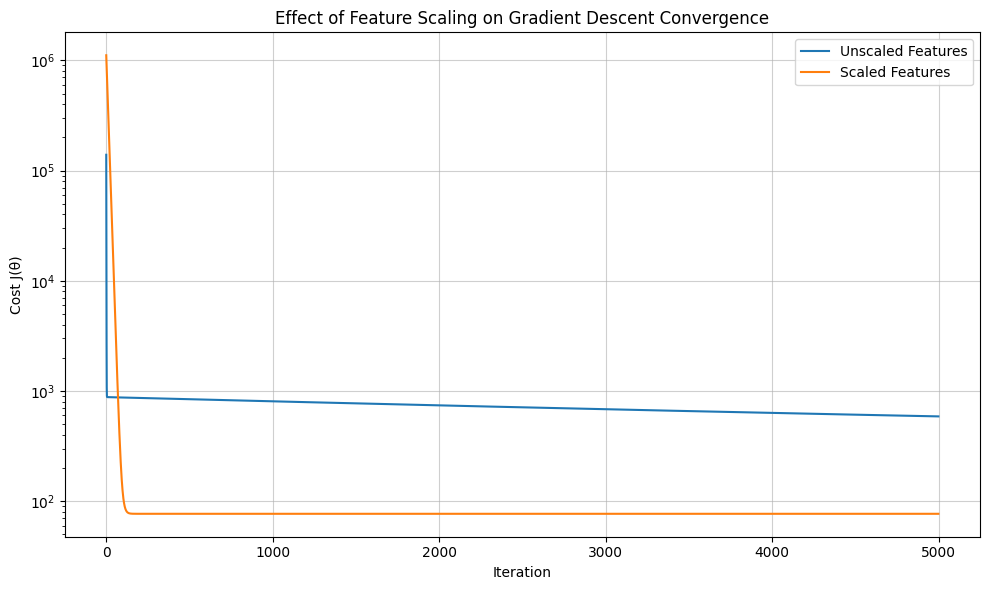

In [50]:
# 6. Compare the convergence with and without feature scaling

plt.figure(figsize=(10, 6))
plt.plot(cost_history_unscaled, label='Unscaled Features')
plt.plot(cost_history_scaled, label='Scaled Features')
plt.xlabel("Iteration")
plt.ylabel("Cost J(θ)")
plt.title("Effect of Feature Scaling on Gradient Descent Convergence")
plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.6)
plt.tight_layout()
plt.show()


In [61]:
# 7. Define the Normal Equation solution

def normal_equation(X, y):
    return np.linalg.solve(X.T @ X, X.T @ y)

# Calculate the closed form solution
theta_normal = normal_equation(X_multiple, y_multiple)

# Convert scaled Gradient Descent parameters back to the original feature space
theta_scaled_original = np.zeros(N_FEATURES + 1)

theta_scaled_original[1:] = theta_scaled[1:] / feature_std
theta_scaled_original[0] = (theta_scaled[0] - np.sum((theta_scaled[1:] *feature_mean) / feature_std))

# Compare all parameter vectors
parameter_comparison = pd.DataFrame({
    "True Parameters": true_theta_multiple,
    "Gradient Descent Unscaled": theta_unscaled,
    "Gradient Descent Scaled": theta_scaled_original,
    "Normal Equation": theta_normal},
                                     
    index=["theta_0", "theta_1", "theta_2", "theta_3", "theta_4"]
)

parameter_comparison.head(10)

,True Parameters,Gradient Descent Unscaled,Gradient Descent Scaled,Normal Equation
theta_0,120.0,0.003479,120.328728,120.328728
theta_1,4.0,1.476782,4.012371,4.012371
theta_2,0.8,1.688945,0.806978,0.806978
theta_3,15.0,0.160171,14.660957,14.660957
theta_4,-2.5,-0.306228,-2.551444,-2.551444


In [63]:
# 8. Compare predictions from Gradient Descent and Normal Equation

y_pred_gradient_descent = X_multiple @ theta_scaled_original
y_pred_normal_equation = X_multiple @ theta_normal

mse_gradient_descent = np.mean((y_pred_gradient_descent - y_multiple) ** 2)
mse_normal_equation = np.mean((y_pred_normal_equation - y_multiple) ** 2)

prediction_comparison = pd.DataFrame({
    "Model": [
        "Gradient Descent",
        "Normal Equation"
    ],
    "MSE": [
        mse_gradient_descent,
        mse_normal_equation
    ]
})

prediction_comparison.head()

,Model,MSE
0,Gradient Descent,153.294905
1,Normal Equation,153.294905


In [64]:
# 9. Calculate the coefficient of determination R²

def r_squared(y_true, y_pred):
    residual_sum_squares = np.sum((y_true - y_pred) ** 2)
    total_sum_squares = np.sum((y_true - y_true.mean()) ** 2)
    
    r2 = 1 - residual_sum_squares / total_sum_squares
    
    return r2

r2_gradient_descent = r_squared(y_multiple, y_pred_gradient_descent)
r2_normal_equation = r_squared(y_multiple, y_pred_normal_equation)

model_evaluation = pd.DataFrame({
    "Model": [
        "Gradient Descent",
        "Normal Equation"
    ],
    "MSE": [
        mse_gradient_descent,
        mse_normal_equation
    ],
    "R²": [
        r2_gradient_descent,
        r2_normal_equation
    ]
})

model_evaluation.head()

,Model,MSE,R²
0,Gradient Descent,153.294905,0.919389
1,Normal Equation,153.294905,0.919389


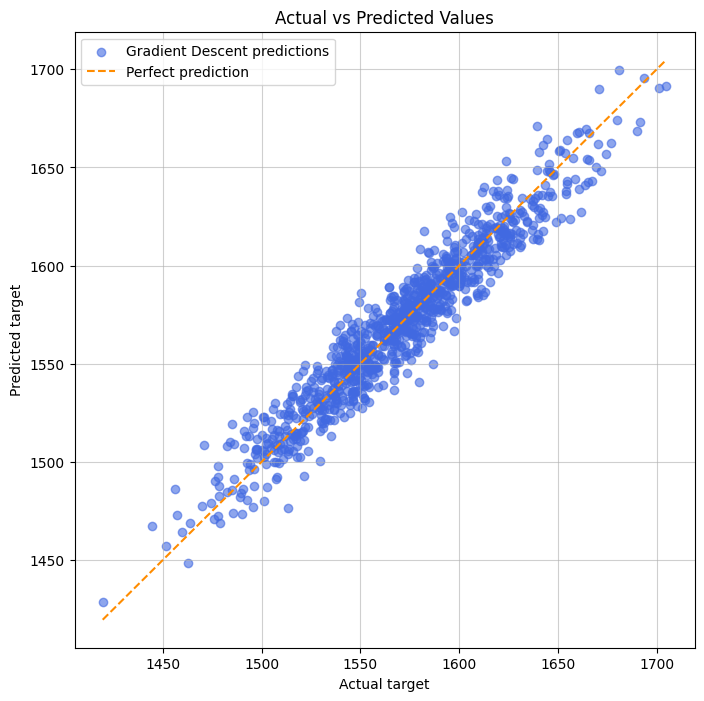

In [73]:
# 10. Visualize the final prediction accuracy

plt.figure(figsize=(8, 8))
plt.scatter(
    y_multiple,
    y_pred_gradient_descent,
    color='royalblue',
    alpha=0.6,
    label="Gradient Descent predictions"
)

minimum_value = min(y_multiple.min(), y_pred_gradient_descent.min())
maximum_value = max(y_multiple.max(), y_pred_gradient_descent.max())

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
    color='darkorange',
    label="Perfect prediction"
)

plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Actual vs Predicted Values")
plt.legend()
plt.grid(True, alpha=0.6)
plt.show()


In [74]:
# 11. Display the final optimization summary

final_summary = pd.DataFrame({
    "Metric": [
        "Simple Regression Final Cost",
        "Multiple Regression GD Final Cost",
        "Multiple Regression Normal Equation Cost",
        "Gradient Descent R²",
        "Normal Equation R²",
        "Number of Multiple Regression Samples",
        "Number of Multiple Regression Features",
        "Gradient Descent Iterations"
    ],
    "Value": [
        cost_history_simple[-1],
        cost_history_scaled[-1],
        compute_cost(X_multiple, y_multiple, theta_normal),
        r2_gradient_descent,
        r2_normal_equation,
        M_SAMPLES_MULTIPLE,
        N_FEATURES,
        N_ITERATIONS_MULTIPLE
    ]
})

final_summary

,Metric,Value
0,Simple Regression Final Cost,1.991618
1,Multiple Regression GD Final Cost,76.647453
2,Multiple Regression Normal Equation Cost,76.647453
3,Gradient Descent R²,0.919389
4,Normal Equation R²,0.919389
5,Number of Multiple Regression Samples,1000.000000
6,Number of Multiple Regression Features,4.000000
7,Gradient Descent Iterations,5000.000000
